#**Hands-On Activity 9 | Exploring Data Visually**





---



Name : Benj Federic C. De Leon<br>
Course Code and Title : CPE 031 - Visualizations and Data Analysis<br>
Date Submitted : October 16, 2026 <br>
Instructor : Engr. Jimlord M. Quejado


---



**1. Objectives:**

This activity aims to demonstrate students’ ability to visually explore and analyze data using Python. Students will learn how to summarize and visualize categorical, quantitative, time-series, and geospatial data for exploratory data analysis (EDA).

**2. Intended Learning Outcomes (ILOs):**

By the end of this module the students should be able to demonstrate:
1. Analyze various visualization techniques to determine how data representation methods influence understanding, perception, and decision-making.

2. Evaluate existing visualizations in terms of accuracy, clarity, aesthetics, and accessibility, providing justified recommendations for improvement.

3. Create effective, insightful, and user-centered visualizations by integrating appropriate design principles, data encoding techniques, and visualization tools.

**3. Discussions:**

Exploratory Data Analysis (EDA) is the process of analyzing datasets to summarize their main characteristics and gain insights before formal modeling. Visual exploration helps identify trends, relationships, and data quality issues.

Key Components:

Univariate Analysis:
Analyzing one variable at a time (e.g., histograms, bar charts).

Bivariate Analysis:
Exploring relationships between two variables (e.g., scatterplots, crosstabs).

Missing Data Analysis:
Identifying and handling missing or null values.

Time-Series Visualization:
Displaying data across time to reveal trends or seasonality.

Geospatial Visualization:
Mapping data to geographical regions to identify spatial patterns.

EDA is both an art and science combining statistical summaries with visual intuition.

**4. Procedures:**

**Color and Perception**

Section 1: Organizing and Exploring Data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Sample dataset
data = {
    "Product": ["Juice", "Smoothie", "Juice", "Smoothie", "Juice", "Smoothie"],
    "Region": ["North", "South", "East", "West", "North", "East"],
    "Sales": [120, 150, 90, 110, 130, 170],
    "Profit": [30, 45, 20, 25, 35, 50]
}
df = pd.DataFrame(data)

# Display the dataset
df

,Product,Region,Sales,Profit
0,Juice,North,120,30
1,Smoothie,South,150,45
2,Juice,East,90,20
3,Smoothie,West,110,25
4,Juice,North,130,35
5,Smoothie,East,170,50


Task 1: Analyzing Variables One at a Time

/tmp/ipykernel_787/2975764973.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Region", data=df, palette="Set2")


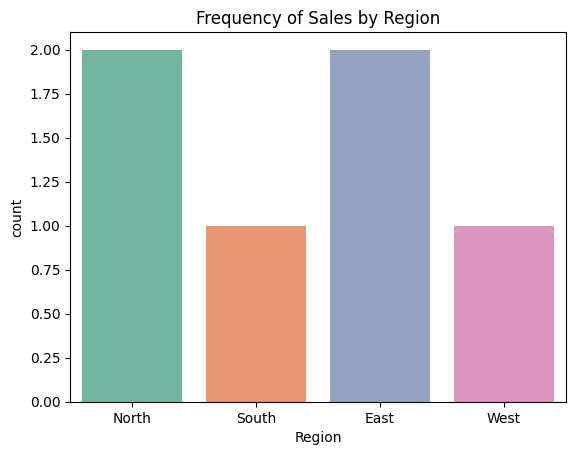

In [ ]:
#Categorical Variable
# Countplot for categorical variable
sns.countplot(x="Region", data=df, palette="Set2")
plt.title("Frequency of Sales by Region")
plt.show()


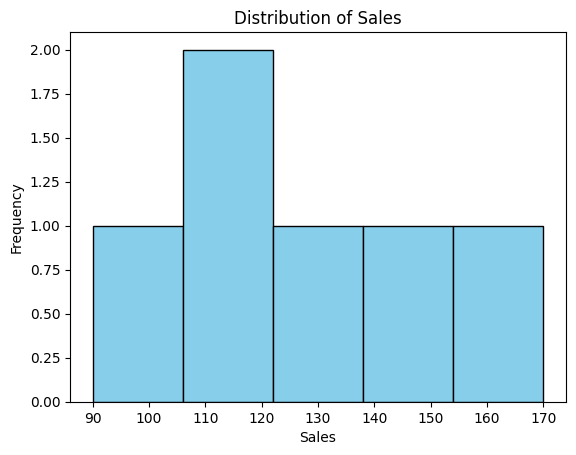

In [ ]:
#Quantitative Variable
# Histogram for quantitative variable
plt.hist(df["Sales"], bins=5, color="skyblue", edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

Task: <br>
Create one countplot for Product and one histogram for Profit. <br>
Compare their patterns and interpret what they mean.

/tmp/ipykernel_787/1804553941.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Product", data=df, palette="Set2")


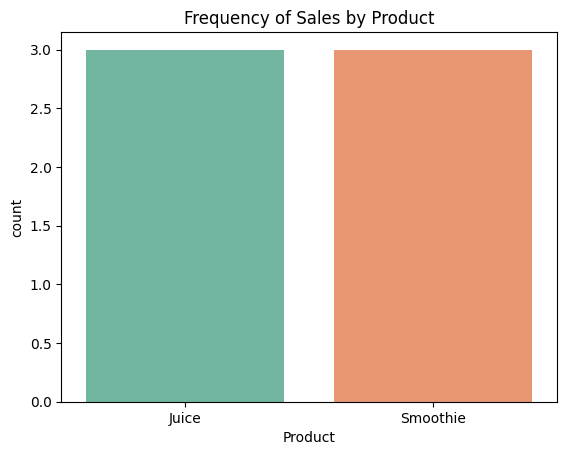

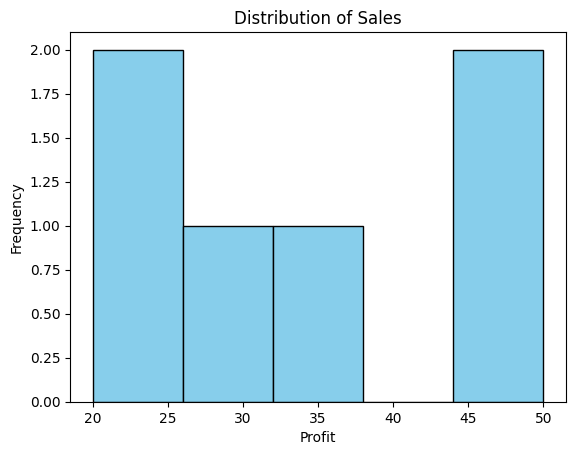

In [ ]:

# Countplot for product
sns.countplot(x="Product", data=df, palette="Set2")
plt.title("Frequency of Sales by Product")
plt.show()

#Histogram for Profit
plt.hist(df["Profit"], bins=5, color="skyblue", edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

**Observation:** The countplot shows Juice and Smoothie both have 3 records each, so the products are evenly split. The profit histogram is more spread out. Most profits are at the low end (20-26) and the high end (44-50), and there's nothing in the middle (38-44).

Section 2: Relationships Between Variables

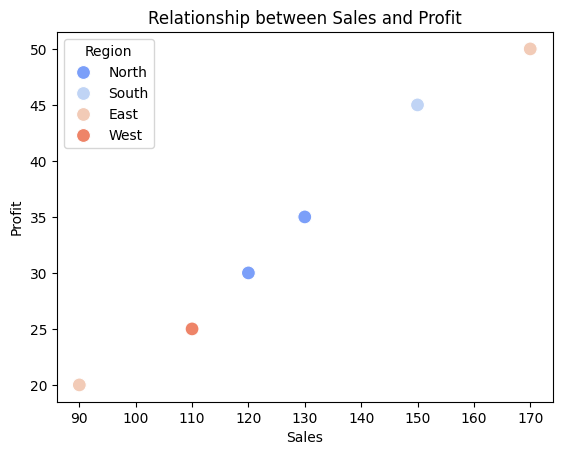

In [ ]:
# Scatterplot: Sales vs Profit
sns.scatterplot(x="Sales", y="Profit", hue="Region", data=df, palette="coolwarm", s=100)
plt.title("Relationship between Sales and Profit")
plt.show()

In [ ]:
# Crosstabulation example
pd.crosstab(df["Region"], df["Product"], values=df["Sales"], aggfunc="mean").fillna(0)


Product,Juice,Smoothie
Region,,
East,90.0,170.0
North,125.0,0.0
South,0.0,150.0
West,0.0,110.0


Task: <br>
Interpret whether higher sales also mean higher profit. <br>
Which region seems to perform best?

**Answer:** Yes, higher sales usually mean higher profit. The East region contains both the highest single revenue/profit generator and the lowest, suggesting potential variance between sub-regions or individual stores within the East.

Section 3: Analysis of Missing Data

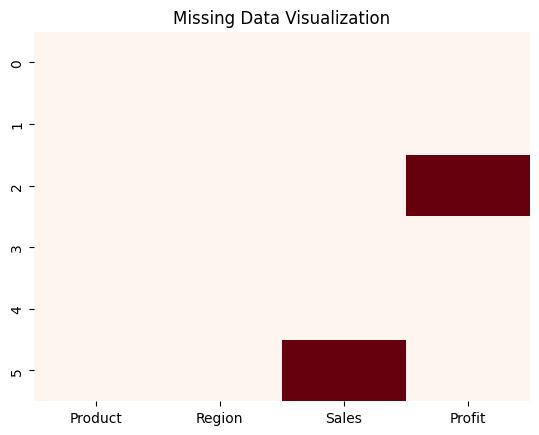

,0
Product,0
Region,0
Sales,1
Profit,1


In [ ]:
# Introduce missing data
df_missing = df.copy()
df_missing.loc[2, "Profit"] = np.nan
df_missing.loc[5, "Sales"] = np.nan

# Visualize missing data
sns.heatmap(df_missing.isnull(), cbar=False, cmap="Reds")
plt.title("Missing Data Visualization")
plt.show()

# Display missing summary
df_missing.isnull().sum()


Task: <br>
Describe what you observe in the missing data visualization. <br>
Which variables need attention before analysis?


**Answer:** The heatmap shows two red spots, one in Profit (row 2) and one in Sales (row 5). The missing Profit value in Row 2 and the missing Sales value in Row 5 that needed attention before analysis.

Section 4: Visualizing Time-Series Data

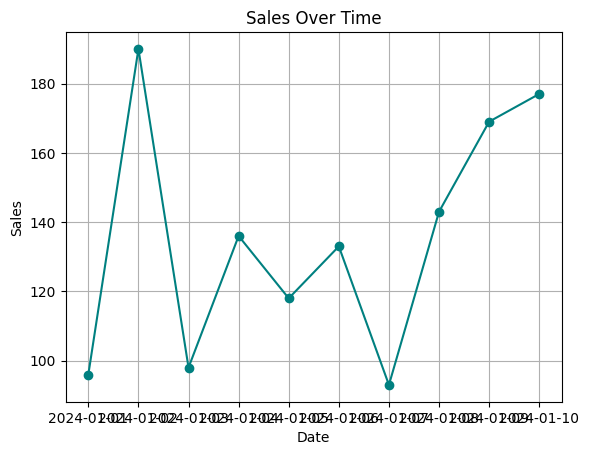

In [ ]:
# Generate time-series example
dates = pd.date_range(start="2024-01-01", periods=10)
sales = np.random.randint(80, 200, 10)
ts_df = pd.DataFrame({"Date": dates, "Sales": sales})

# Line chart for time-series
plt.plot(ts_df["Date"], ts_df["Sales"], marker="o", color="teal")
plt.title("Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

Task: <br>
Add a moving average line (rolling mean) to smooth fluctuations. <br>
Hint: Use ts_df["Sales"].rolling(window=3).mean().

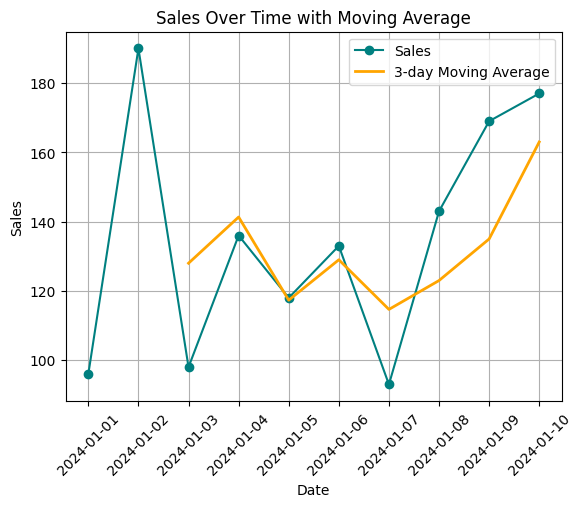

In [ ]:
#Add a moving average (rolling mean) to smooth the line
ts_df["Moving Average"] = ts_df["Sales"].rolling(window=3).mean()

plt.plot(ts_df["Date"], ts_df["Sales"], marker="o", color="teal", label="Sales")
plt.plot(ts_df["Date"], ts_df["Moving Average"], color="orange", linewidth=2, label="3-day Moving Average")
plt.title("Sales Over Time with Moving Average")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.show()

Section 5: Visualizing Geospatial Data

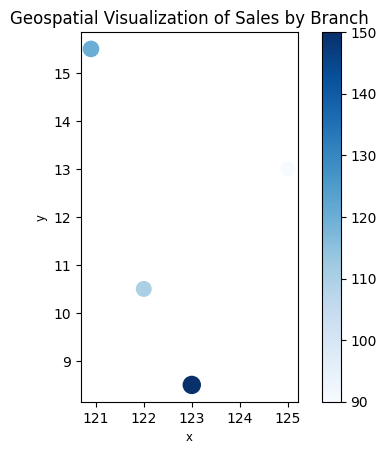

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

# Sample coordinates (latitude, longitude)
coords = {
    "Branch": ["North", "South", "East", "West"],
    "Latitude": [15.5, 8.5, 13.0, 10.5],
    "Longitude": [120.9, 123.0, 125.0, 122.0],
    "Sales": [120, 150, 90, 110]
}

geo_df = pd.DataFrame(coords)
geo_df["geometry"] = [Point(xy) for xy in zip(geo_df.Longitude, geo_df.Latitude)]
gdf = gpd.GeoDataFrame(geo_df, geometry="geometry")

# Plot simple map (Philippines outline optional if available)
gdf.plot(column="Sales", cmap="Blues", legend=True, markersize=geo_df["Sales"])
plt.title("Geospatial Visualization of Sales by Branch")
plt.show()

Task: <br>
Interpret which branch has the highest sales geographically. <br>
How can such visualization help in business decision-making?

**Answer:** The branch with the highest sale is at (123, 8.5) shows the darkest shade of blue, corresponding to 150 in sales. Visualizing geographic clusters helps identify lucrative sub-regions for expanding new branches or closing redundant/underperforming ones.

**5. Supplementary Activity**

Create your own mini exploratory analysis:

1. Choose a dataset (e.g., from Kaggle, or a CSV file you have).

2. Perform:

*   Univariate analysis (1 categorical + 1 quantitative)
*   Bivariate analysis (scatterplot or crosstab)
*   Missing data visualization
*   Time-series or geospatial visualization (choose one)
3. Summarize your key insights using visual interpretation.

***Dataset:*** Video Game Sales from Kaggle (https://www.kaggle.com/datasets/gregorut/videogamesales).

In [ ]:
#Load the Video Game Sales dataset (Kaggle)
import pandas as pd

df = pd.read_csv('/content/vgsales.csv')

df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


**Univariate Analysis**

/tmp/ipykernel_787/780163311.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Genre", data=games, palette="Set2", order=games["Genre"].value_counts().index)


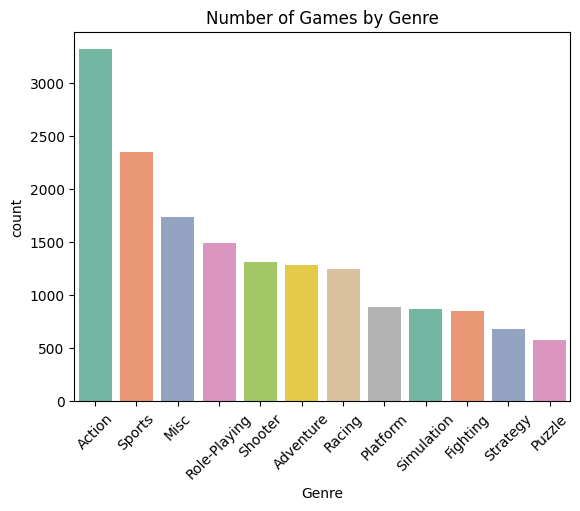

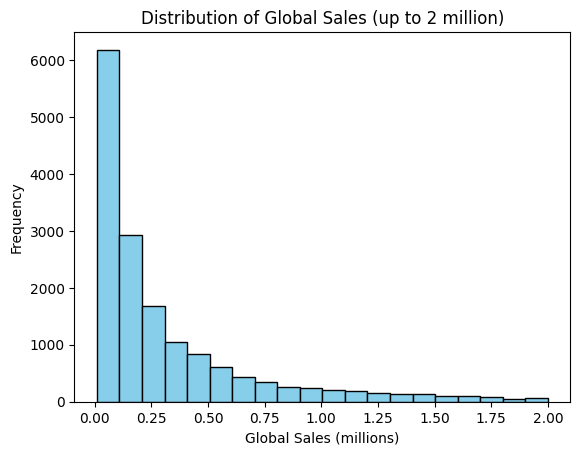

In [ ]:
#Categorical variable: Genre
sns.countplot(x="Genre", data=games, palette="Set2", order=games["Genre"].value_counts().index)
plt.title("Number of Games by Genre")
plt.xticks(rotation=45)
plt.show()

#Quantitative variable: Global_Sales
plt.hist(games[games["Global_Sales"] <= 2]["Global_Sales"], bins=20, color="skyblue", edgecolor="black")
plt.title("Distribution of Global Sales (up to 2 million)")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Frequency")
plt.show()

**Bivariate Analysis**

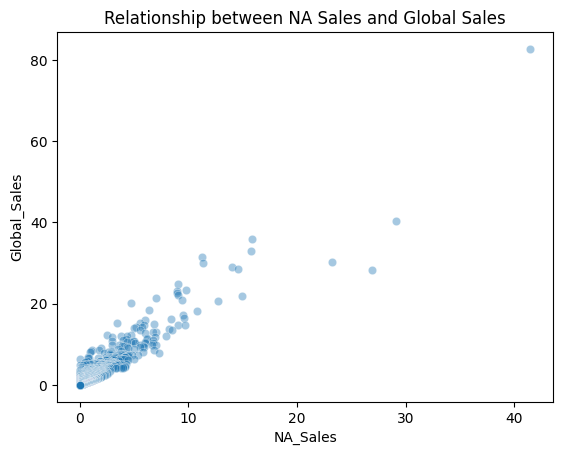

Platform,DS,PS2,PS3,Wii,X360
Genre,,,,,
Action,0.34,0.78,0.81,0.50,0.75
Adventure,0.20,0.11,0.31,0.22,0.32
Fighting,0.20,0.62,0.68,0.57,0.58
Misc,0.35,0.46,0.39,0.79,0.73
Platform,0.84,0.70,0.82,1.56,0.47
Puzzle,0.35,0.33,0.20,0.28,0.12
Racing,0.58,0.72,0.80,0.65,0.63
Role-Playing,0.63,0.50,0.63,0.40,0.95
Shooter,0.20,0.68,1.26,0.44,1.37


In [ ]:
#Scatterplot: NA_Sales vs Global_Sales
sns.scatterplot(x="NA_Sales", y="Global_Sales", data=games, alpha=0.4)
plt.title("Relationship between NA Sales and Global Sales")
plt.show()

#Crosstabulation: average global sales by genre and platform (top 5 platforms)
top_platforms = ["PS2", "X360", "PS3", "Wii", "DS"]
top_games = games[games["Platform"].isin(top_platforms)]
pd.crosstab(top_games["Genre"], top_games["Platform"], values=top_games["Global_Sales"], aggfunc="mean").round(2)

**Missing Data Visualization**

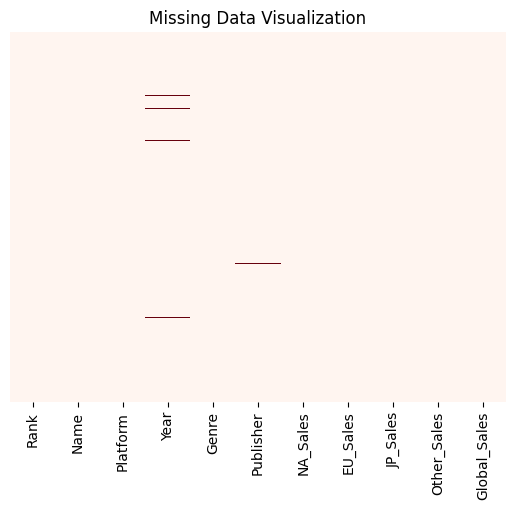

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


In [ ]:
#Visualize missing data
sns.heatmap(games.isnull(), cbar=False, cmap="Reds", yticklabels=False)
plt.title("Missing Data Visualization")
plt.show()

#Display missing summary
games.isnull().sum()

**Time-Series Visualization**

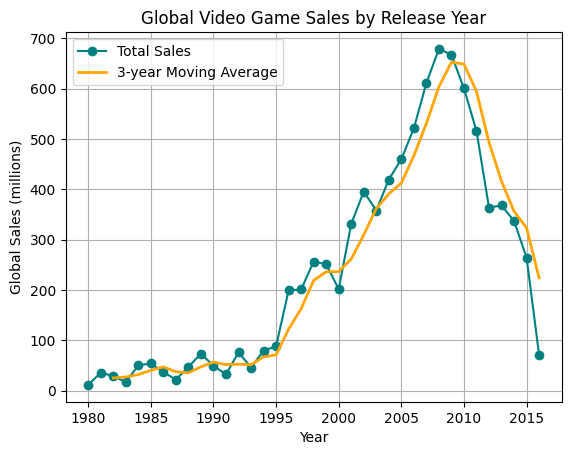

In [ ]:
#Total global sales per release year
yearly = games.groupby("Year")["Global_Sales"].sum().reset_index()

#Remove 2017 and 2020 because they only have a few games
yearly = yearly[yearly["Year"] <= 2016]

#Moving average to smooth the line
yearly["Moving Average"] = yearly["Global_Sales"].rolling(window=3).mean()

plt.plot(yearly["Year"], yearly["Global_Sales"], marker="o", color="teal", label="Total Sales")
plt.plot(yearly["Year"], yearly["Moving Average"], color="orange", linewidth=2, label="3-year Moving Average")
plt.title("Global Video Game Sales by Release Year")
plt.xlabel("Year")
plt.ylabel("Global Sales (millions)")
plt.grid(True)
plt.legend()
plt.show()

**Key Insights:**

1.Action is the most common genre, followed by Sports. Puzzle and Strategy are among the least common.<br>
2.Most games sold less than 0.5 million copies. .<br>
3.NA sales and global sales go up together. The scatterplot trends upward, so a game that sells well in North America usually sells well worldwide too.<br>
4.In the missing data heatmap, only Year and Publisher have missing values.<br>
5.Total sales by release year went up during the 1990s and early 2000s, peaked around the late 2000s, then went down.

**6. Conclusion/Learnings/Analysis:**

In this activity I learned how to explore data using visuals in Python. I used countplots and histograms to look at one variable, scatterplots and crosstabs to look at two variables, a heatmap to find missing data, a line chart with a moving average for time-series, and a map for location data. I also learned that missing values should be checked first so the results are correct, and that a moving average makes a messy line easier to read. Overall, visualizing the data first helps me understand it better before doing any deeper analysis.